# Customer Churn Prediction: Random Forest vs XGBoost
Dataset: IBM Telco Customer Churn (7,043 customers) from Karggel. Goal: predict which customers will leave

In [ ]:
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve, ConfusionMatrixDisplay)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split
from xgboost import XGBClassifier

SEED = 42
%matplotlib inline

## 1. Load and explore the data

In [ ]:
raw = pd.read_csv("data/telco.csv")
print(raw.shape)
raw.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
print(raw["Churn"].value_counts(normalize=True).round(3))
raw.dtypes.value_counts()

Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


str        18
int64       2
float64     1
Name: count, dtype: int64

Churn is imbalanced (about 26.5% Yes), so accuracy alone will be misleading. ROC-AUC, recall and F1 matter more.

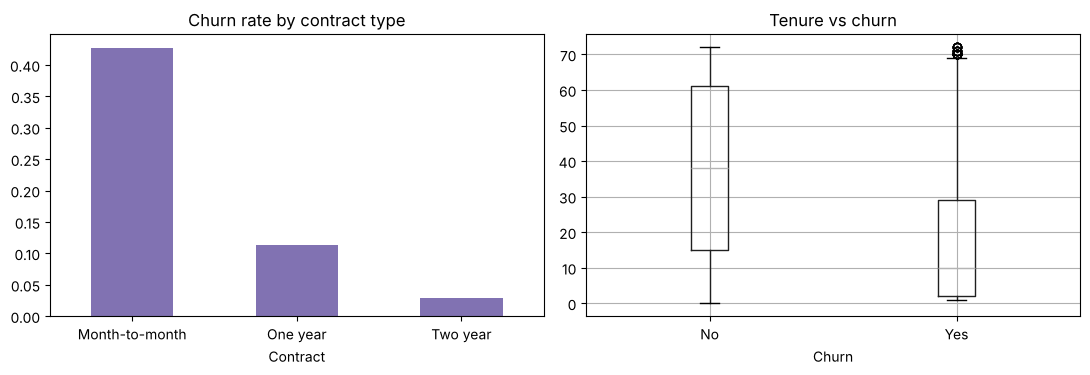

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
raw.groupby("Contract")["Churn"].apply(lambda s: (s == "Yes").mean()).plot.bar(ax=axes[0], rot=0, color="#8172B2")
axes[0].set_title("Churn rate by contract type")
raw.boxplot(column="tenure", by="Churn", ax=axes[1])
axes[1].set_title("Tenure vs churn"); plt.suptitle("")
plt.tight_layout(); plt.show()

Month-to-month customers and customers with short tenure churn the most.

## 2. Clean and encode

In [ ]:
df = raw.copy()

# TotalCharges is text; brand-new customers (tenure 0) have a blank value
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Blank TotalCharges:", df["TotalCharges"].isna().sum())
df["TotalCharges"] = df["TotalCharges"].fillna(0)

df = df.drop(columns=["customerID"])
df["Churn"] = (df["Churn"] == "Yes").astype(int)

cat_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
df = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)

X = df.drop(columns=["Churn"])
y = df["Churn"]
print("Features:", X.shape[1])

Blank TotalCharges: 11
Features: 30


## 3. Train/test split
Stratified so both sets keep the same churn ratio.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
imbalance = (y_train == 0).sum() / (y_train == 1).sum()
print(f"Train {len(X_train)}, test {len(X_test)}, scale_pos_weight = {imbalance:.2f}")

Train 5634, test 1409, scale_pos_weight = 2.77


## 4. Random Forest
Bagging: many trees trained independently on random samples, then averaged. `class_weight='balanced'` handles the imbalance.

In [ ]:
rf_params = {
    "n_estimators": [200, 300, 500],
    "max_depth": [6, 8, 10, 12, None],
    "min_samples_leaf": [1, 3, 5, 10],
    "max_features": ["sqrt", 0.3, 0.5],
}
rf_search = RandomizedSearchCV(
    RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1),
    rf_params, n_iter=20, scoring="roc_auc", cv=cv, random_state=SEED, n_jobs=-1)

t0 = time.time()
rf_search.fit(X_train, y_train)
rf_time = time.time() - t0
rf = rf_search.best_estimator_
print(rf_search.best_params_, f"CV AUC = {rf_search.best_score_:.4f}", f"time = {rf_time:.1f}s")

{'n_estimators': 200, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 8} CV AUC = 0.8476 time = 85.3s


## 5. XGBoost
Boosting: shallow trees built one after another, each correcting the previous ones' errors. `scale_pos_weight` handles the imbalance.

In [ ]:
xgb_params = {
    "n_estimators": [200, 300, 500],
    "max_depth": [3, 4, 5, 6],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "reg_lambda": [1, 3, 5],
}
xgb_search = RandomizedSearchCV(
    XGBClassifier(scale_pos_weight=imbalance, eval_metric="logloss", random_state=SEED, n_jobs=-1),
    xgb_params, n_iter=20, scoring="roc_auc", cv=cv, random_state=SEED, n_jobs=-1)

t0 = time.time()
xgb_search.fit(X_train, y_train)
xgb_time = time.time() - t0
xgb = xgb_search.best_estimator_
print(xgb_search.best_params_, f"CV AUC = {xgb_search.best_score_:.4f}", f"time = {xgb_time:.1f}s")

{'subsample': 0.8, 'reg_lambda': 1, 'n_estimators': 500, 'max_depth': 4, 'learning_rate': 0.01, 'colsample_bytree': 0.8} CV AUC = 0.8491 time = 15.6s


## 6. Evaluate on the test set

In [ ]:
def evaluate(name, model, train_time, cv_auc):
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    return {"model": name,
            "accuracy": accuracy_score(y_test, pred),
            "precision": precision_score(y_test, pred),
            "recall": recall_score(y_test, pred),
            "f1": f1_score(y_test, pred),
            "roc_auc": roc_auc_score(y_test, proba),
            "cv_auc": cv_auc,
            "train_time_s": train_time}, proba, pred

rf_res, rf_proba, rf_pred = evaluate("Random Forest", rf, rf_time, rf_search.best_score_)
xgb_res, xgb_proba, xgb_pred = evaluate("XGBoost", xgb, xgb_time, xgb_search.best_score_)
results = pd.DataFrame([rf_res, xgb_res]).set_index("model").round(4)
results

,accuracy,precision,recall,f1,roc_auc,cv_auc,train_time_s
model,,,,,,,
Random Forest,0.7544,0.5244,0.8048,0.6350,0.8436,0.8476,85.3435
XGBoost,0.7488,0.5172,0.8021,0.6289,0.8463,0.8491,15.6398


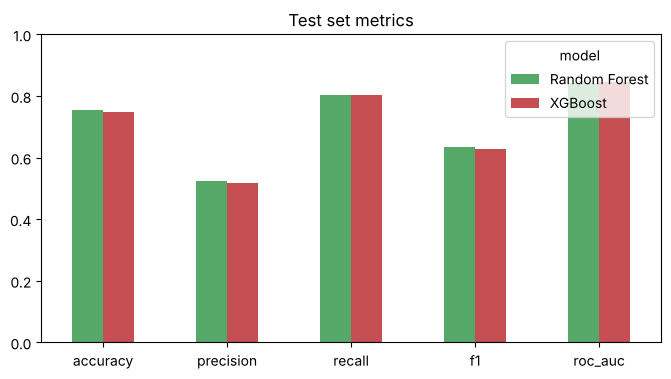

In [ ]:
metrics = ["accuracy", "precision", "recall", "f1", "roc_auc"]
results[metrics].T.plot.bar(figsize=(8, 4), rot=0, color=["#55A868", "#C44E52"])
plt.ylim(0, 1); plt.title("Test set metrics"); plt.show()

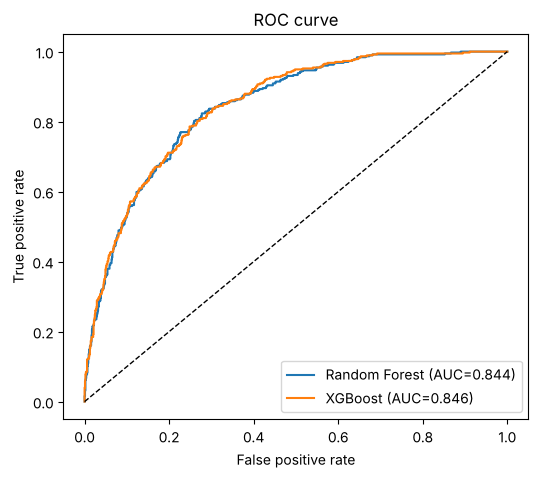

In [ ]:
plt.figure(figsize=(6, 5))
for name, proba in [("Random Forest", rf_proba), ("XGBoost", xgb_proba)]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curve"); plt.legend(); plt.show()

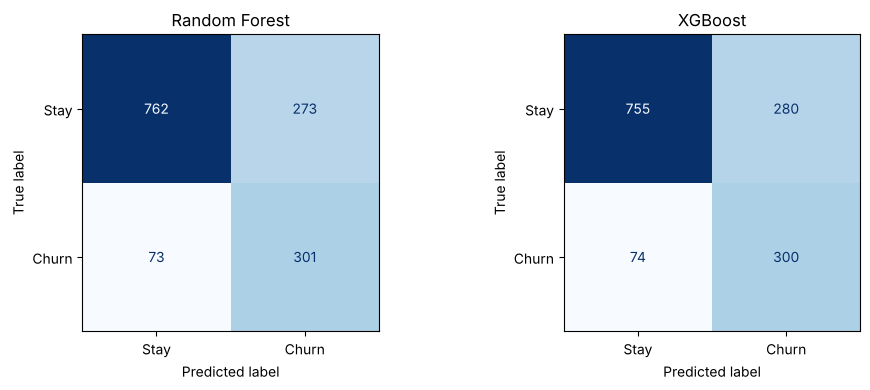

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name, pred in [(axes[0], "Random Forest", rf_pred), (axes[1], "XGBoost", xgb_pred)]:
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Stay", "Churn"]).plot(
        ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout(); plt.show()

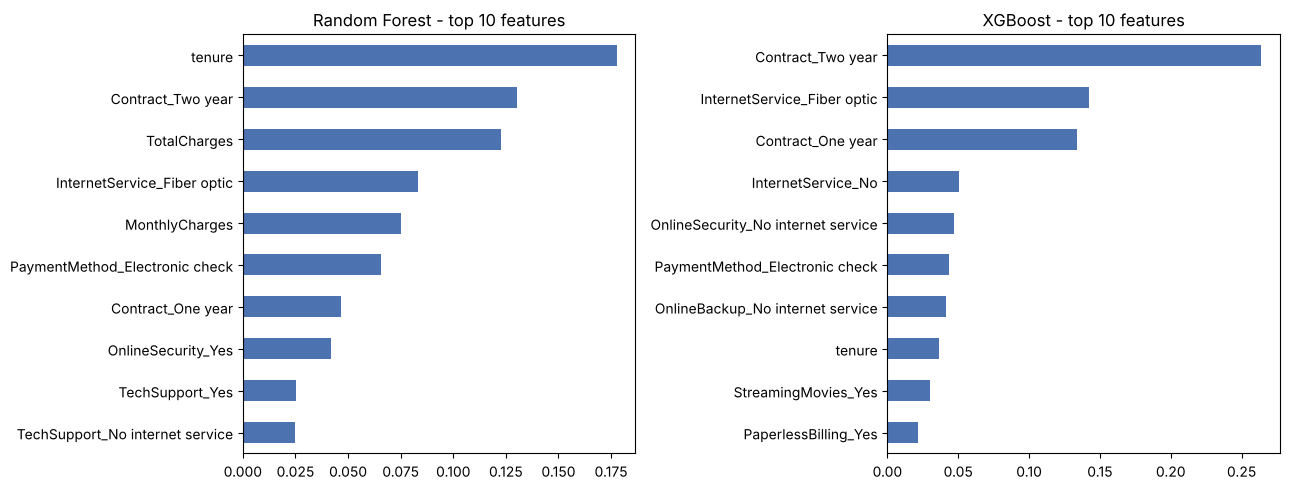

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, name, model in [(axes[0], "Random Forest", rf), (axes[1], "XGBoost", xgb)]:
    pd.Series(model.feature_importances_, index=X.columns).nlargest(10).sort_values().plot.barh(ax=ax, color="#4C72B0")
    ax.set_title(f"{name} - top 10 features")
plt.tight_layout(); plt.show()

## 7. Why XGBoost came out slightly ahead

- **Better ROC-AUC on both CV and test**, so the edge is consistent and not luck of one split.
- **Boosting vs bagging:** Random Forest averages independent trees (reduces variance). XGBoost adds trees sequentially, each fixing the last one's errors (reduces bias), so it handles borderline customers better.
- **Regularisation:** a small learning rate (0.01), shallow trees (depth 4), L2 penalty and subsampling keep it from overfitting on 7k rows.
- **Speed:** about 5x faster to tune, because shallow trees are cheap and XGBoost is heavily optimised.
- **Honest note:** Random Forest is marginally better on accuracy/F1 at the 0.5 threshold. The gap is tiny because a few strong features (contract type, tenure, charges) dominate, so both models hit a similar ceiling.

## 8. Conclusion
XGBoost is the pick: better ranking ability (AUC), faster and more tunable. Both models catch about 80% of churners. Next steps: tune the decision threshold for business cost, add SHAP explanations, and engineer features such as tenure groups.